# Product coding and uphold likelihood

Two models, both on intake text only (the complaint and the factual background). The ombudsman's reasoning and the outcome wording are not in the features.

* **Product.** Stratified random holdout. A complaints MI code is a category, and the category list is stable, so a random split is the right check of whether the narrative identifies the product.
* **Uphold.** Split by decision date, with no date shared between train, validation and test. The test period is the latest 15% of decisions. Validation is the 15% before that. The threshold and the probability calibration are fit on validation only.

The uphold label is the published ombudsman outcome. It is not the firm's own accept/reject decision at week one. Most complaints never reach an ombudsman.

In [1]:
import json
import os
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src" / "fos_triage").exists() and (ROOT.parent / "src" / "fos_triage").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import average_precision_score, brier_score_loss, f1_score, roc_auc_score

metrics = json.loads(Path("reports/metrics.json").read_text())
product = metrics["product"]
uphold = metrics["uphold"]
data = metrics["dataset"]
print(f"Corpus {data['n']:,} decisions, {data['from']} to {data['to']}, uphold rate {data['upheld_rate']:.1%}")
print(f"Median intake characters: {data['median_chars']:.0f}")
print("Text source", data["text_source"])


Corpus 3,099 decisions, 2022-05-17 to 2026-10-06, uphold rate 37.0%
Median intake characters: 1242
Text source {'pdf': 3099}


## Product coder

The baseline predicts the most common training product for every case. Macro F1 is the headline number because the products are uneven.

Holdout macro F1 0.957  (majority baseline 0.049)
Accuracy 0.960  (majority baseline 0.281)
Majority class: Banking and Payments
Same coder on a later-period slice: macro F1 0.943, accuracy 0.959

Investments               0.900
Claims Management         0.945
Consumer Credit           0.951
PPI                       0.957
Banking and Payments      0.960
Mortgages                 0.974
Pensions and Annuities    0.976
Insurance                 0.977
Funeral plans             0.977

Largest confusions
     4  Consumer Credit  ->  Banking and Payments
     3  Banking and Payments  ->  Consumer Credit
     3  Banking and Payments  ->  Investments
     3  Insurance  ->  Investments
     2  Pensions and Annuities  ->  Investments
     1  Banking and Payments  ->  Insurance


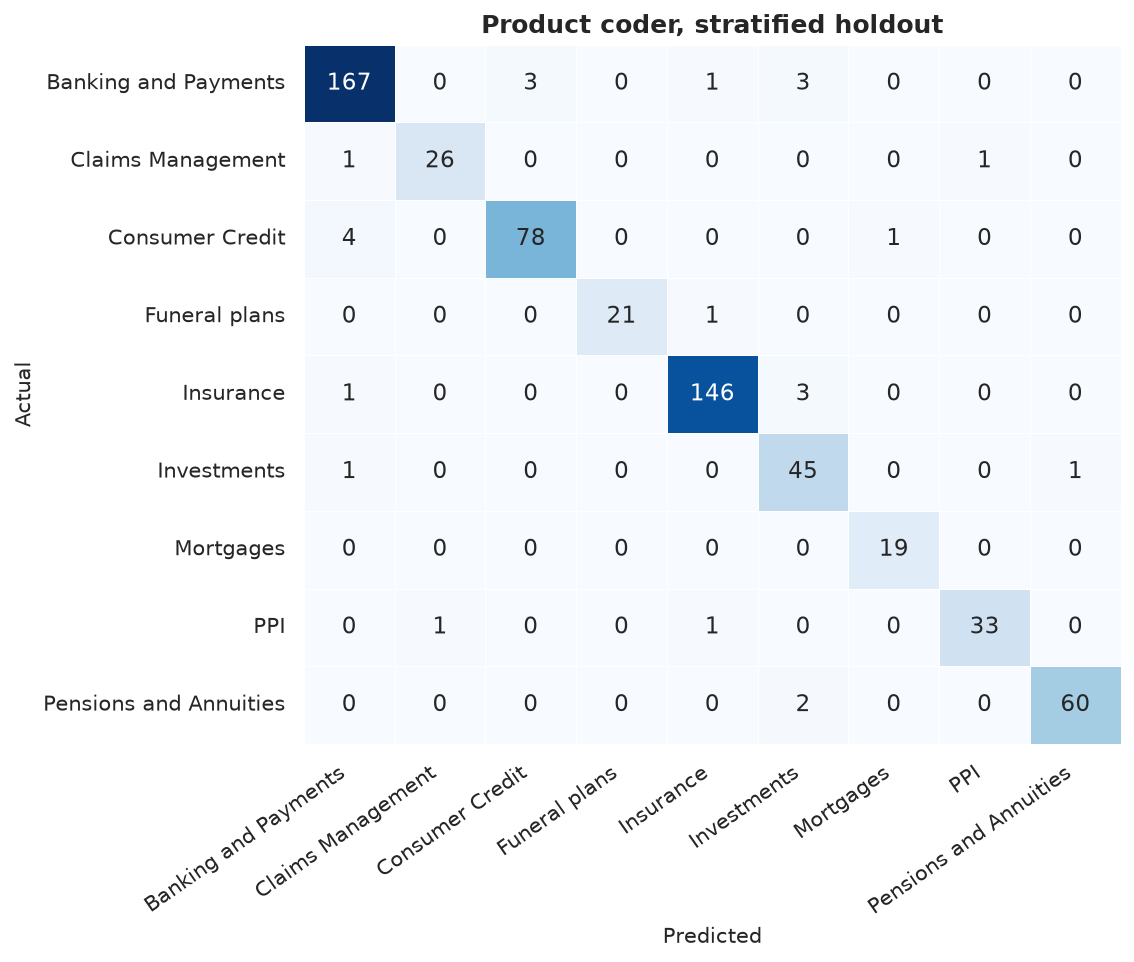

Phrases the linear model uses (top coefficients)
  Banking and Payments: account, card, bank, scam, credit card, money
  Claims Management: fee, claim, claims, pursue, instructed, mis
  Consumer Credit: loan, agreement, car, finance, credit, hire
  Funeral plans: funeral, plan, funeral plan, op, dignity, paid funeral
  Insurance: policy, insurance, claim, insurance policy, damage, cover
  Investments: shares, isa, investment, bond, investments, stocks
  Mortgages: mortgage, property, rate, mr mrs, mortgages, application
  PPI: ppi, payment protection, protection insurance, ppi policy, protection, policy
  Pensions and Annuities: pension, sipp, personal pension, transfer, annuity, pensions


In [2]:
print(f"Holdout macro F1 {product['macro_f1']:.3f}  (majority baseline {product['majority_baseline_macro_f1']:.3f})")
print(f"Accuracy {product['accuracy']:.3f}  (majority baseline {product['majority_baseline_accuracy']:.3f})")
print(f"Majority class: {product['majority_class']}")
if "time_split_macro_f1" in product:
    print(f"Same coder on a later-period slice: macro F1 {product['time_split_macro_f1']:.3f}, accuracy {product['time_split_accuracy']:.3f}")
print()
print(pd.Series(product["per_class_f1"], name="f1").sort_values().round(3).to_string())
print()
print("Largest confusions")
for row in product["top_confusions"][:6]:
    print(f"  {row['n']:4d}  {row['true']}  ->  {row['predicted']}")
display(Image("reports/figures/cm_product.png"))
print("Phrases the linear model uses (top coefficients)")
for label, words in product["top_coefficients"].items():
    print(f"  {label}: {', '.join(words['towards_class'][:6])}")


## Uphold likelihood

Probabilities are Platt-scaled on the validation period. The decision threshold maximises validation F1. Test numbers below are computed again from the saved holdout file, not copied by hand.

Saved test period {'n': 487, 'from': '2026-09-30', 'to': '2026-10-06', 'upheld_rate': 0.2587268993839836}
Recomputed from holdout file {'n': 487, 'from': '2026-09-30', 'to': '2026-10-06', 'positive_rate': 0.259, 'roc_auc': 0.682, 'average_precision': 0.471, 'brier': 0.176, 'f1': 0.462, 'recall': 0.698, 'precision': 0.345}
Majority-class accuracy 0.741, majority F1 0.000
Brier of always predicting the training rate 0.216 (model Brier 0.176)
Confusion [[tn, fp], [fn, tp]] [[194, 167], [38, 88]]


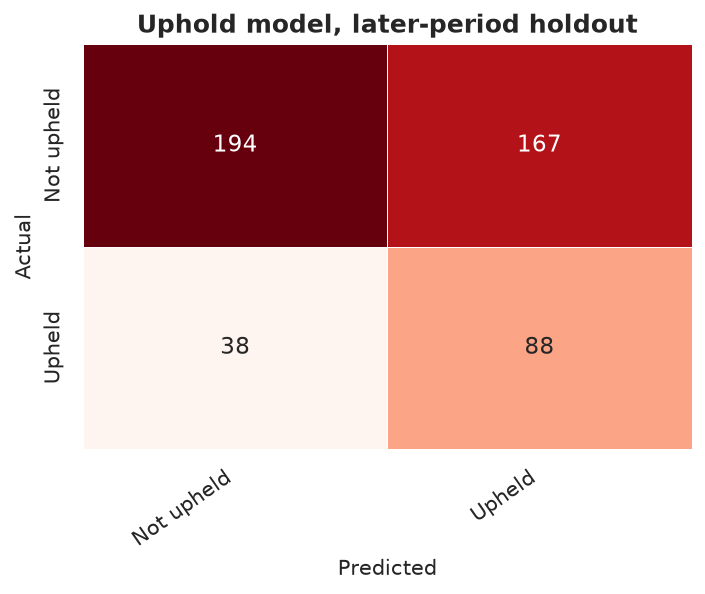

Coefficients toward an uphold (uncalibrated linear score)
  up: delays, transfer, claim, offered, advice, instructed, dealership, received, caused, despite
  down: halifax, mr, cover, explained, lloyds, says, cancelled, unhappy, prudential, mortgage


In [3]:
holdout = pd.read_csv("reports/uphold_holdout.csv")
threshold = uphold["threshold"]
proba = holdout.proba
y = holdout.upheld
pred = (proba >= threshold).astype(int)
recomputed = {
    "n": int(len(holdout)),
    "from": holdout.date.min(),
    "to": holdout.date.max(),
    "positive_rate": float(y.mean()),
    "roc_auc": float(roc_auc_score(y, proba)),
    "average_precision": float(average_precision_score(y, proba)),
    "brier": float(brier_score_loss(y, proba)),
    "f1": float(f1_score(y, pred)),
    "recall": float(((pred == 1) & (y == 1)).sum() / max(int((y == 1).sum()), 1)),
    "precision": float(((pred == 1) & (y == 1)).sum() / max(int((pred == 1).sum()), 1)),
}
print("Saved test period", uphold["test"])
print("Recomputed from holdout file", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in recomputed.items()})
print(f"Majority-class accuracy {uphold['majority_baseline_accuracy']:.3f}, majority F1 {uphold['majority_baseline_f1']:.3f}")
print(f"Brier of always predicting the training rate {uphold['base_rate_brier']:.3f} (model Brier {recomputed['brier']:.3f})")
print("Confusion [[tn, fp], [fn, tp]]", uphold["confusion_matrix"])
display(Image("reports/figures/cm_uphold.png"))
print("Coefficients toward an uphold (uncalibrated linear score)")
coef = uphold["top_coefficients"]
label = next(iter(coef))
print("  up:", ", ".join(coef[label]["towards_positive"][:10]))
print("  down:", ", ".join(coef[label]["towards_negative"][:10]))


## Errors

High-confidence mistakes are the ones a queue design has to live with. Quotes are the intake text, capped, with the decision reference so the case can be read on the FOS site.

In [4]:
examples = json.loads(Path("reports/error_examples.json").read_text())
for kind in ("false_positives", "false_negatives"):
    print("\n", kind)
    for row in examples[kind]:
        print(f"  {row['reference']} {row['date']} {row['product']} p={row['probability']:.2f} actual_upheld={row['upheld']}")
        print(f"    {row['quote'][:220]}")



 false_positives
  DRN-6567019 2026-10-01 Insurance p=0.58 actual_upheld=0
    Mr K complains that esure Insurance Limited mishandled a claim he made on his vehicle insurance policy. esure is the underwriter of this policy, i.e. the insurer. Part of this complaint concerns the actions of esure's ag
  DRN-6544754 2026-09-30 Pensions and Annuities p=0.57 actual_upheld=0
    Mr G has complained that St James's Place Wealth Management Plc (“SJP”) gave him unsuitable advice when it recommended he not transfer his Defined Benefits (“DB”) pension scheme in 2021. The Cash Equivalent Transfer Valu
  DRN-6270605 2026-10-05 Insurance p=0.55 actual_upheld=0
    Mr L and Mrs L are unhappy their claim for accidental damage was unfairly declined by Admiral Insurance (Gibraltar) Limited (“Admiral”) under their home insurance policy. Mrs L made a claim when her window cleaner accide
  DRN-6480312 2026-10-02 Insurance p=0.53 actual_upheld=0
    Mr K is unhappy with how AXA Insurance UK Plc (“AXA”) hand

## What the score would do to a queue

The minutes below are **assumptions**, not a time study. The catch-rate is measured on the later-period holdout.

Two operating points are shown. The validation threshold maximises F1 and favours recall. A stricter score of 0.40 is what the demo calls the high-priority queue. Both cuts are choices, not properties of the ombudsman.

In [5]:
for cut, name in [(threshold, "validation threshold"), (0.40, "high-priority cut 0.40")]:
    queued = proba >= cut
    caught = ((y == 1) & queued).sum()
    precision = y[queued].mean() if queued.any() else float("nan")
    print(f"{name}: {queued.mean():.1%} of holdout, precision {precision:.1%}, share of upheld cases caught {caught / y.sum():.1%}")
print()
print("Assumptions, labelled as such:")
print("- A handler spends 8 minutes coding a new complaint and writing the first case note.")
print("- A suggested product code and a two-sentence note save 3 of those minutes. The handler still reads the complaint.")
print("- Illustrative book: 10,000 complaints a year. This is not a forecast for any firm.")
saved_hours = 10000 * 3 / 60
print(f"- Implied saving: {saved_hours:,.0f} hours a year, before any specialist-queue effect.")
print("The 8-week DISP clock still runs. The score does not close a case.")
if "transformer_uphold" in metrics:
    t = metrics["transformer_uphold"]
    print()
    print(f"DistilBERT on the same date split: ROC-AUC {t.get('roc_auc'):.3f}, F1 {t.get('f1'):.3f}, Brier {t.get('brier'):.3f}")
else:
    print()
    print("No transformer block in metrics.json. The served model is the calibrated TF-IDF logistic regression.")


validation threshold: 52.4% of holdout, precision 34.5%, share of upheld cases caught 69.8%
high-priority cut 0.40: 13.3% of holdout, precision 55.4%, share of upheld cases caught 28.6%

Assumptions, labelled as such:
- A handler spends 8 minutes coding a new complaint and writing the first case note.
- A suggested product code and a two-sentence note save 3 of those minutes. The handler still reads the complaint.
- Illustrative book: 10,000 complaints a year. This is not a forecast for any firm.
- Implied saving: 500 hours a year, before any specialist-queue effect.
The 8-week DISP clock still runs. The score does not close a case.

DistilBERT on the same date split: ROC-AUC 0.579, F1 0.408, Brier 0.225


## Case note

Extractive summary on a quoted complaint from the committed sample. No external API.

In [6]:
import json
from fos_triage.summarize import extractive_summary, key_issues
sample = [json.loads(line) for line in Path("data/sample/decisions.jsonl").read_text().splitlines() if line.strip()]
row = sample[0]
print(row["reference"], row["product"], row["date"])
print(extractive_summary(row["model_text"]))
print(key_issues(row["model_text"]))


DRN-3376512 Claims Management 2022-05-17
Mr M complains about Sanderson Drake Limited (SDL) and their refusal to agree a repayment plan.
['sanderson drake limited sdl', 'repayment plan', 'refusal']
